## Cleaning Census Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
from matplotlib.lines import Line2D
from IPython.display import display

#### Helper Functions

In [2]:
def clean_census_types(df,rename_map,float_cols=("median_age", "avg_hh_size"),id_widths=None):
    """Return cleaned copy and the available ACS column names"""
    
    df = df.copy().rename(columns=rename_map)
    if id_widths is None:
        id_widths = {"geoid": 11,"county": 3,"state": 2, "tract": 6}

    acs_cols = [name for code, name in rename_map.items() if code != "NAME" and name in df.columns]

    for col in acs_cols:
        dtype = "float64" if col in float_cols else "Int64"
        df[col] = pd.to_numeric(df[col], errors="coerce").astype(dtype)
    for col, width in id_widths.items():
        ids = (df[col].astype("string").str.strip().replace({"": pd.NA, "nan": pd.NA, "None": pd.NA}).str.replace(r"\.0$", "", regex=True))

        valid = ids.str.fullmatch(rf"\d{{1,{width}}}", na=False)
        invalid = ids.notna() & ~valid

        if invalid.any():
            raise ValueError(f"Invalid {col} values: {ids[invalid].head().tolist()}")

        df[col] = ids.str.zfill(width)

    return df, acs_cols


def clean_sentinels(df,acs_cols, sentinel_threshold=-1e8, topcode_col="median_hh_income",topcode_value=250001):
    """Return flagged original data & a copy with sentinels removed"""
    
    df = df.copy()
    acs_cols = list(acs_cols)

    vals = df[acs_cols].astype("float64")
    is_sent = vals < sentinel_threshold

    df["has_sentinel"] = is_sent.any(axis=1)

    if topcode_col is not None:
        df["income_topcoded"] = (df[topcode_col].eq(topcode_value).fillna(False))

    viz = df.copy()
    viz[acs_cols] = vals.mask(is_sent)

    return df, viz


def estimate_missing_vehicles(df, vehicle_weights=None,target_col="aggregate_vehicles",household_col="total_hh",flag_col="vehicles_estimated"):
    
    """Fill missing totals when all vehicle components are available"""
    df = df.copy()

    if vehicle_weights is None:
        vehicle_weights = {"hh_veh_1": 1,"hh_veh_2": 2,"hh_veh_3": 3,"hh_veh_4plus": 4}

    if not vehicle_weights:
        raise ValueError("vehicle_weights must not be empty.")

    columns = list(vehicle_weights)

    estimates = (df[columns].mul(pd.Series(vehicle_weights), axis="columns").sum(axis=1, min_count=len(columns)))

    gap = (df[target_col].isna() & estimates.notna() & df[household_col].gt(0)).fillna(False)

    if flag_col in df.columns:
        previous_flags = df[flag_col].fillna(False).astype(bool)
    else:
        previous_flags = pd.Series(False, index=df.index)

    # Allow fractional estimates if different weights
    df[target_col] = df[target_col].astype("float64")
    df.loc[gap, target_col] = estimates[gap]
    df[flag_col] = previous_flags | gap

    return df

def prep_geography(df, county_names, geometry_col="geometry", county_col="county", name_col="county_name", source_crs="EPSG:4326", target_crs="EPSG:3310"):
    """Accept WKT/geometry objects & preserve existing CRS"""
    
    df = df.copy()

    if not isinstance(df[geometry_col].dtype, gpd.array.GeometryDtype):
        df[geometry_col] = gpd.GeoSeries.from_wkt(df[geometry_col],index=df.index)

    gdf = gpd.GeoDataFrame(df, geometry=geometry_col)

    if gdf.crs is None:
        gdf = gdf.set_crs(source_crs)

    gdf = gdf.to_crs(target_crs)
    gdf[name_col] = gdf[county_col].map(county_names)

    return gdf

def pct(numerator, denominator):
    """Return percentages- missing/nonpositive denominators produce NaN."""
    return 100 * numerator / denominator.where(denominator > 0)

def add_indicators(df, indicators):
    """
    Add percentage columns without modifying the input.

    {"output": ("numerator_column", "denominator_column")}

    All listed components must be available to calculate
    """
    df = df.copy()

    for output, (numerator, denominator) in indicators.items():
        if isinstance(numerator, str):
            values = df[numerator]
        else:
            columns = list(numerator)

            if not columns:
                raise ValueError(f"No numerator columns supplied for {output}.")

            values = df[columns].sum(axis=1, min_count=len(columns))

        df[output] = pct(values, df[denominator])

    return df

def plot_choropleths(gdf, maps, ncols=2, figsize=None, cmap="viridis", scheme="quantiles", k=5):
    """Plot any number of mapped columns; return figure and axes."""
    
    if not maps:
        raise ValueError("maps must contain at least one column")
    if ncols < 1:
        raise ValueError("ncols must be at least 1")

    ncols = min(ncols, len(maps))
    nrows = (len(maps) + ncols - 1) // ncols

    if figsize is None:
        figsize = (7 * ncols, 6 * nrows)

    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, squeeze=False)

    for ax, (column, title) in zip(axes.flat, maps.items()):
        options = {}
        if scheme is not None:
            options = {"scheme": scheme, "k": k}

        gdf.plot(column=column, cmap=cmap,legend=True, ax=ax,linewidth=0.1, edgecolor="white", missing_kwds={"color": "lightgray"}, **options)

        ax.set_title(title)
        ax.set_axis_off()

    for ax in list(axes.flat)[len(maps):]:
        ax.set_visible(False)

    return fig, axes

def plot_grouped_scatter(df, x, y, group_col, colors, size_col=None, size_scale=40, quantile=None, figsize=(8, 6.5)):
    """Plot grouped points w/optional bubble sizes & quantile lines."""
    
    if size_scale <= 0:
        raise ValueError("size_scale must be positive.")

    if quantile is not None and not 0 <= quantile <= 1:
        raise ValueError("quantile must be between 0 and 1.")

    required = list(dict.fromkeys(
        [x, y, group_col] + ([size_col] if size_col else [])
    ))
    plot_data = df.dropna(subset=required).copy()

    if size_col is not None:
        plot_data = plot_data.loc[plot_data[size_col] >= 0]

    groups = plot_data[group_col].unique()
    missing_colors = [name for name in groups if name not in colors]

    if missing_colors:
        raise ValueError(f"Missing colors for: {missing_colors}")

    fig, ax = plt.subplots(figsize=figsize)

    for name, group in plot_data.groupby(group_col, observed=True):
        sizes = 40 if size_col is None else group[size_col] / size_scale

        ax.scatter( group[x], group[y], s=sizes, alpha=0.5, color=colors[name], edgecolor="white", linewidth=0.3)

    # Use each full input column, matching the original percentile logic
    if quantile is not None:
        x_cutoff = df[x].quantile(quantile)
        y_cutoff = df[y].quantile(quantile)

        if pd.notna(x_cutoff):
            ax.axvline(x_cutoff, color="gray", ls="--", lw=0.8)
        if pd.notna(y_cutoff):
            ax.axhline(y_cutoff, color="gray", ls="--", lw=0.8)

    handles = [
        Line2D(
            [0], [0],
            marker="o",
            ls="",
            color=color,
            label=name,
            markersize=8,
            alpha=0.7,
        )
        for name, color in colors.items()
        if name in groups]

    ax.legend(handles=handles, frameon=False)
    ax.spines[["top", "right"]].set_visible(False)

    return fig, ax

### Converting applicable columns into Int or Float types, and leaving IDs in string formats

In [3]:
rename_map = {
    "NAME": "tract_name",
    "B03002_001E": "total_pop", "B03002_003E": "nh_white", "B03002_004E": "nh_black",
    "B03002_005E": "nh_aian", "B03002_006E": "nh_asian", "B03002_007E": "nh_nhpi",
    "B03002_008E": "nh_other_race", "B03002_009E": "nh_two_or_more", "B03002_012E": "hispanic_latino",
    "B01002_001E": "median_age", "B09001_001E": "pop_under_18",
    "B01001_020E": "male_65_66", "B01001_021E": "male_67_69", "B01001_022E": "male_70_74",
    "B01001_023E": "male_75_79", "B01001_024E": "male_80_84", "B01001_025E": "male_85_plus",
    "B01001_044E": "female_65_66", "B01001_045E": "female_67_69", "B01001_046E": "female_70_74",
    "B01001_047E": "female_75_79", "B01001_048E": "female_80_84", "B01001_049E": "female_85_plus",
    "B19013_001E": "median_hh_income", "B19113_001E": "median_family_income", "B19301_001E": "per_capita_income",
    "C17002_001E": "poverty_universe", "C17002_002E": "ratio_u050", "C17002_003E": "ratio_050_099",
    "C17002_004E": "ratio_100_124", "C17002_005E": "ratio_125_149", "C17002_006E": "ratio_150_184",
    "C17002_007E": "ratio_185_199",
    "B22003_002E": "hh_snap",
    "B08201_001E": "total_hh", "B08201_002E": "hh_veh_0", "B08201_003E": "hh_veh_1",
    "B08201_004E": "hh_veh_2", "B08201_005E": "hh_veh_3", "B08201_006E": "hh_veh_4plus",
    "B25046_001E": "aggregate_vehicles", "B25010_001E": "avg_hh_size",
    "B08301_001E": "total_workers", "B08301_010E": "workers_transit",
    "B08301_019E": "workers_walk", "B08301_021E": "workers_wfh",
    }

data_path = "/home/jovyan/cityplanning_proj/selected_census_data"

selected_census_data = pd.read_csv(
    data_path,
    dtype={
        "geoid": "string",
        "county": "string",
        "state": "string",
        "tract": "string",
    })

selected_census_data, acs_cols = clean_census_types(selected_census_data,rename_map)

# check for NaNs
missing_counts = selected_census_data[acs_cols].isna().sum()
print(missing_counts[missing_counts > 0])

aggregate_vehicles    24
dtype: int64


In [4]:
display(selected_census_data.loc[selected_census_data["total_pop"].eq(0)])

,tract_name,total_pop,nh_white,nh_black,nh_aian,nh_asian,nh_nhpi,nh_other_race,nh_two_or_more,hispanic_latino,...,total_workers,workers_transit,workers_walk,workers_wfh,state,county,tract,geoid,countyfp,geometry
324,Census Tract 4443.03; Alameda County; California,0,0,0,0,0,0,0,0,0,...,0,0,0,0,06,001,444303,06001444303,1.0,MULTIPOLYGON (((-122.10179291503596 37.5177463...
378,Census Tract 9900; Alameda County; California,0,0,0,0,0,0,0,0,0,...,0,0,0,0,06,001,990000,06013990000,13.0,POLYGON ((-122.40910999965438 37.9206999999330...
620,Census Tract 9900; Contra Costa County; Califo...,0,0,0,0,0,0,0,0,0,...,0,0,0,0,06,013,990000,06013990000,13.0,POLYGON ((-122.40910999965438 37.9206999999330...
859,Census Tract 9804.01; San Francisco County; Ca...,0,0,0,0,0,0,0,0,0,...,0,0,0,0,06,075,980401,06075980401,75.0,MULTIPOLYGON (((-123.00055999994889 37.6951400...
863,Census Tract 9901; San Francisco County; Calif...,0,0,0,0,0,0,0,0,0,...,0,0,0,0,06,075,990100,<NA>,NaN,NaN
864,Census Tract 9902; San Francisco County; Calif...,0,0,0,0,0,0,0,0,0,...,0,0,0,0,06,075,990200,06075990200,75.0,MULTIPOLYGON (((-122.32785034320709 37.7810815...


### Keeping relevant tracts & columns
- 6 Census tracts with no population - AC: 444303, 990000, CC: 990000, SF: 980401, 990100, 990200
- Drop from analysis since our focus is on food deserts that directly affect people
- Columns 'county' & 'countyfp' are redundant from above join, so will drop 'countyfp'

In [5]:
new_df = (selected_census_data.loc[selected_census_data["total_pop"].gt(0)].drop(columns=["countyfp"], errors="ignore").copy())

### Inspecting data before sentinel code cleaning

In [6]:
new_df.info()

print("\nMissing values per column:")
print(new_df.isna().sum())

print("\nSummary before sentinel cleaning:")
display(new_df[["total_pop","median_hh_income","per_capita_income","aggregate_vehicles"]].describe())

<class 'pandas.core.frame.DataFrame'>
Index: 859 entries, 0 to 862
Data columns (total 52 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   tract_name            859 non-null    object 
 1   total_pop             859 non-null    Int64  
 2   nh_white              859 non-null    Int64  
 3   nh_black              859 non-null    Int64  
 4   nh_aian               859 non-null    Int64  
 5   nh_asian              859 non-null    Int64  
 6   nh_nhpi               859 non-null    Int64  
 7   nh_other_race         859 non-null    Int64  
 8   nh_two_or_more        859 non-null    Int64  
 9   hispanic_latino       859 non-null    Int64  
 10  median_age            859 non-null    float64
 11  pop_under_18          859 non-null    Int64  
 12  male_65_66            859 non-null    Int64  
 13  male_67_69            859 non-null    Int64  
 14  male_70_74            859 non-null    Int64  
 15  male_75_79            859 no

,total_pop,median_hh_income,per_capita_income,aggregate_vehicles
count,859.0,859.0,859.0,835.0
mean,4242.98021,-7622443.814901,73585.722934,-1594088.947305
std,1688.6239,71567160.202457,35848.238123,32607818.940253
min,33.0,-666666666.0,8422.0,-666666666.0
25%,3058.5,96193.0,46250.5,1743.5
50%,4028.0,133953.0,68075.0,2551.0
75%,5257.0,178537.0,93292.0,3550.5
max,12378.0,250001.0,250455.0,7820.0


### Flagging sentinel values and estimating the missing vehicle aggregations

In [7]:
new_df, viz = clean_sentinels(new_df, acs_cols, sentinel_threshold=-1e8, topcode_col="median_hh_income",topcode_value=250001)

# note: households with 4+ vehicles are counted as 4
viz = estimate_missing_vehicles(viz)

missing_counts = viz[acs_cols].isna().sum()
print(missing_counts[missing_counts > 0])

median_hh_income        10
median_family_income    21
aggregate_vehicles       2
avg_hh_size              2
dtype: int64


In [8]:
# Summary after sentinel cleaning:
display(viz[["total_pop", "median_hh_income", "per_capita_income"]].describe())

,total_pop,median_hh_income,per_capita_income
count,859.00000,849.000000,859.000000
mean,4242.98021,140150.085984,73585.722934
std,1688.62390,56732.281779,35848.238123
min,33.00000,12908.000000,8422.000000
25%,3058.50000,97417.000000,46250.500000
50%,4028.00000,134211.000000,68075.000000
75%,5257.00000,179194.000000,93292.000000
max,12378.00000,250001.000000,250455.000000


#### Basic Summary Statistics
- Avg tract population size is 4243 people, min: 33, max: 12378
- Avg median household income is $140150, min 12,908, max: 250001 (max is top-coded 250,000+)

- Avg per capita income is $73586, min 8422, max: 250455

- NaN values in aggregate columns

## Creating Visualizations/Charts
#### Prepping Geography & calculating % indicators for visualizations

In [9]:
county_names = {"001": "Alameda", "013": "Contra Costa","075": "San Francisco"}

below200 = [
    "ratio_u050",
    "ratio_050_099",
    "ratio_100_124",
    "ratio_125_149",
    "ratio_150_184",
    "ratio_185_199",
]

indicators = {
    "pct_no_vehicle": ("hh_veh_0", "total_hh"),
    "pct_snap": ("hh_snap", "total_hh"),
    "pct_below_200fpl": (below200, "poverty_universe"),
    "pct_transit": ("workers_transit", "total_workers"),
}

viz = prep_geography(viz, county_names, source_crs="EPSG:4326", target_crs="EPSG:3310")
viz = add_indicators(viz, indicators)

### Choropleths: 

Mapping out
- % households with no vehicle
- % below 200% of poverty
- % receiving SNAP
- median household income

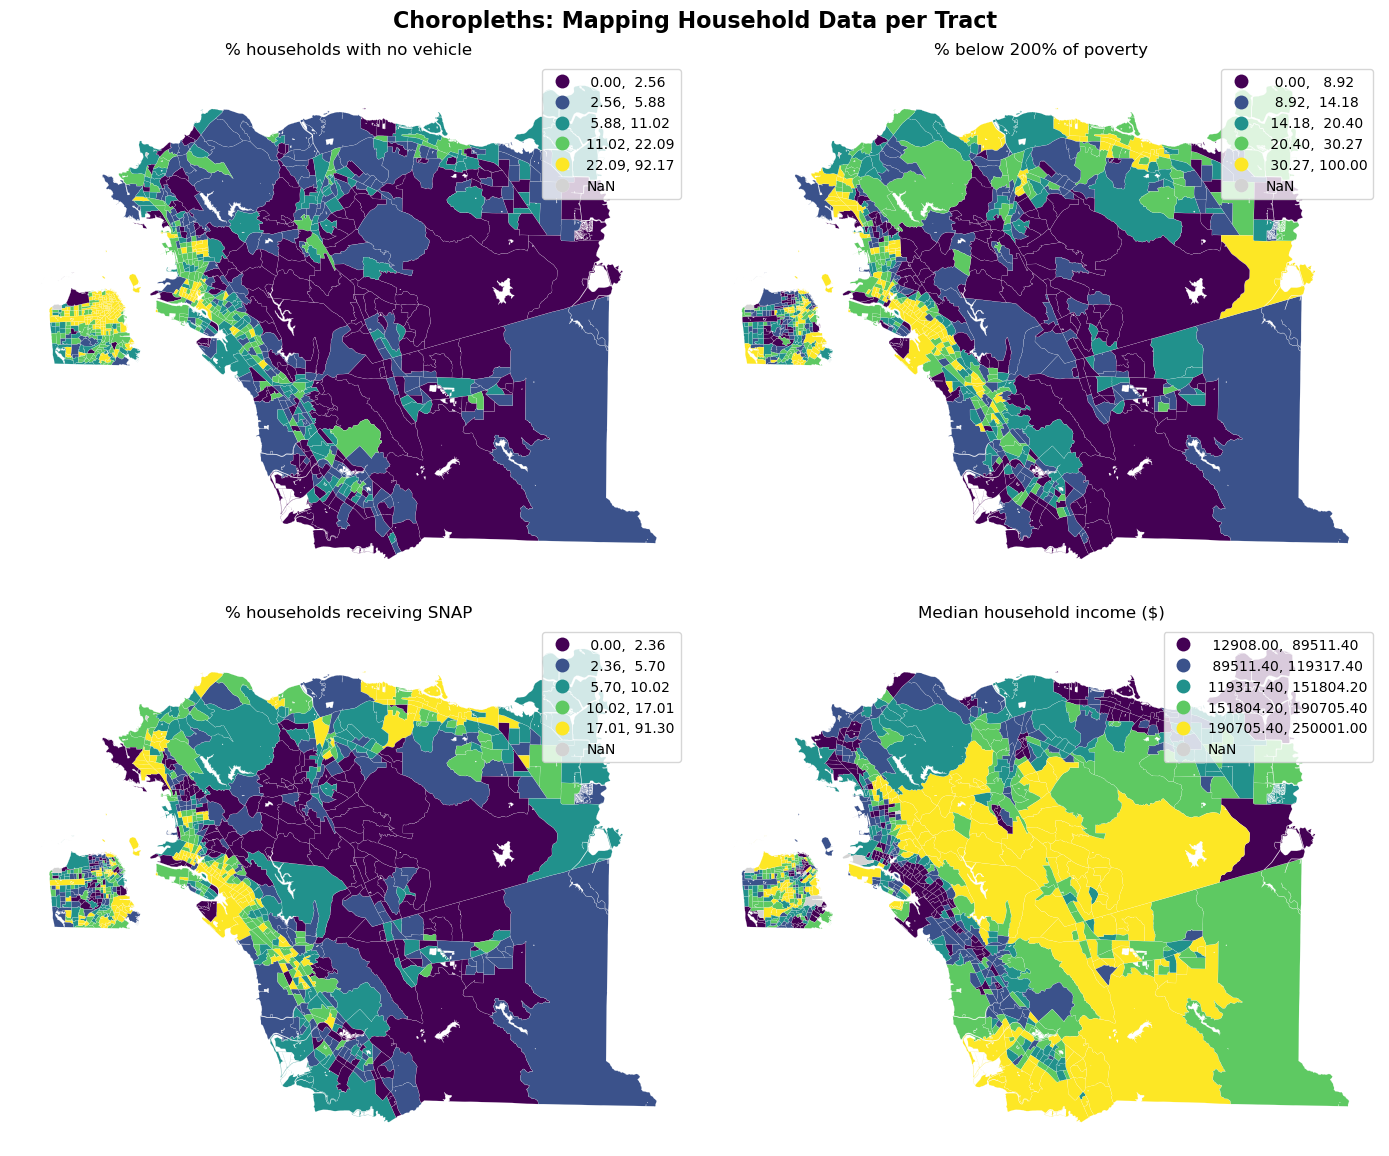

In [10]:
maps = {
    "pct_no_vehicle": "% households with no vehicle",
    "pct_below_200fpl": "% below 200% of poverty",
    "pct_snap": "% households receiving SNAP",
    "median_hh_income": "Median household income ($)",
}

fig, axes = plot_choropleths(viz, maps, ncols=2, scheme= "quantiles", k=5)

# Figure title stays outside the reusable helper.
fig.suptitle("Choropleths: Mapping Household Data per Tract", fontsize=16, fontweight="bold")
fig.tight_layout()
plt.show()

### County Racial Demographics 
- Demographic level charts might not be as applicable right now for analysis, until we target relevant tracts and then look for any racial disparities or mobility related issues

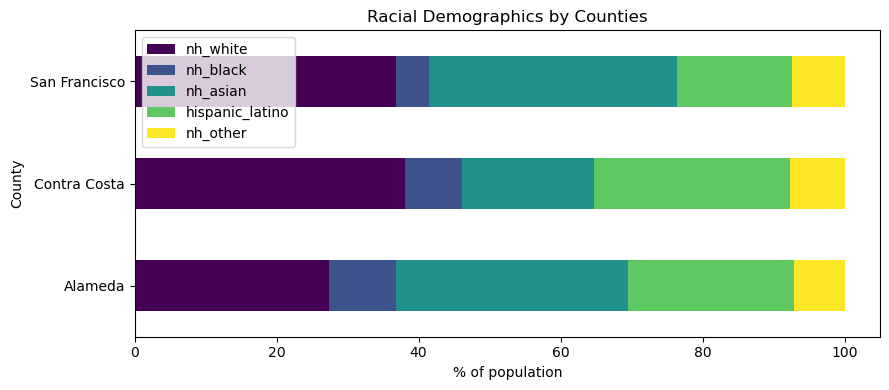

In [11]:
other_race_cols = ["nh_aian", "nh_nhpi", "nh_other_race", "nh_two_or_more"]

viz["nh_other"] = viz[other_race_cols].sum(axis=1, min_count=len(other_race_cols))

race_cols = ["nh_white", "nh_black", "nh_asian", "hispanic_latino", "nh_other"]

comp = (viz.groupby("county_name", observed=True)[race_cols].sum(min_count=1))

county_totals = comp.sum(axis=1, min_count=len(race_cols))
composition_pct = 100 * comp.div(county_totals.where(county_totals > 0), axis=0)

ax = composition_pct.plot(kind="barh", cmap="viridis", stacked=True, figsize=(9, 4))

ax.set_xlabel("% of population")
ax.set_ylabel("County")
ax.set_title("Racial Demographics by Counties")

ax.figure.tight_layout()
plt.show()

### No vehicle vs SNAP Scatter Plot 
- bubble size corresponds to tract population
- dashed lines at 75th percentile to highlight top right quadrant where there is high SNAP & low car access

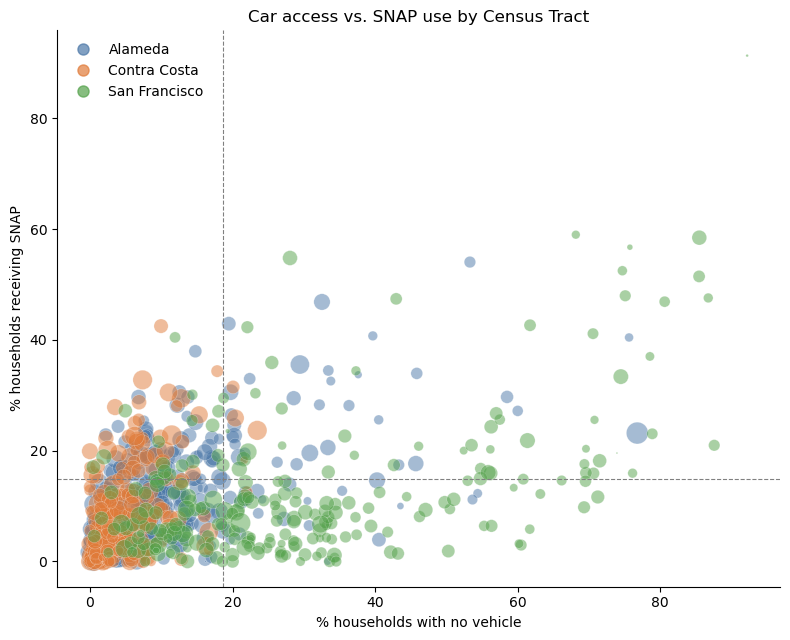

In [12]:
colors = {
    "Alameda": "#4c78a8",
    "Contra Costa": "#e07b39",
    "San Francisco": "#54a24b",
}

fig, ax = plot_grouped_scatter(
    viz,
    x="pct_no_vehicle",
    y="pct_snap",
    group_col="county_name",
    colors=colors,
    size_col="total_pop",
    size_scale=40,
    quantile=0.75,
)

ax.set_xlabel("% households with no vehicle")
ax.set_ylabel("% households receiving SNAP")
ax.set_title("Car access vs. SNAP use by Census Tract")

fig.tight_layout()
plt.show()

Top right quadrant highlights attention on where there is a high percent of households with no vehicle and that receive SNAP, specifically the tracts in Alameda and SF. 

Note: might help to make this chart interactive in the future, since it could help identify each tract and its characteristics as well. 